# Wholesale Customer Segmentation – Clustering Track (Review 2)

**Problem Statement:**
A wholesale distributor in Portugal sells to hundreds of business clients. The goal is to group these clients into **segments with similar purchasing behaviour**, using only their annual spending across six product categories. The distributor can then tailor delivery schedules, pricing and marketing to each segment.

**Dataset:** UCI Machine Learning Repository – *Wholesale Customers* (ID 292), 440 clients.

Clustering is **unsupervised**. The two descriptive columns, `Channel` and `Region`, are **removed before fitting** and used **only afterwards** to interpret and validate the clusters, as the guidelines require.

**Algorithms used:**
1. **K-Means clustering**: *k* is chosen with the Elbow curve (inertia vs. k).
2. **Agglomerative hierarchical clustering**: Dendrogram plus a comparison of linkage strategies (ward, complete, average, single).

**Evaluation:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, PCA 2-D cluster plots and t-SNE plots.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
CLUSTER_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

## 1. Load the Dataset

In [2]:
df = pd.read_csv("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


**Data dictionary** (all spending values are annual, in monetary units, m.u.):

| Column | Description |
|---|---|
| `Fresh` | Annual spending on fresh products |
| `Milk` | Annual spending on milk products |
| `Grocery` | Annual spending on grocery products |
| `Frozen` | Annual spending on frozen products |
| `Detergents_Paper` | Annual spending on detergents and paper products |
| `Delicassen` | Annual spending on delicatessen products (spelling as in the UCI file) |
| `Channel` | 1 = Horeca (Hotel / Restaurant / Café), 2 = Retail. **Not used for fitting.** |
| `Region` | 1 = Lisbon, 2 = Oporto, 3 = Other. **Not used for fitting.** |

## 2. Data Audit

In [3]:
print("Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (440, 8)

Data Types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate Rows: 0


In [4]:
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
label_cols = ["Channel", "Region"]

df[spend_cols].describe().round(1)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.3,5796.3,7951.3,3071.9,2881.5,1524.9
std,12647.3,7380.4,9503.2,4854.7,4767.9,2820.1
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3127.8,1533.0,2153.0,742.2,256.8,408.2
50%,8504.0,3627.0,4755.5,1526.0,816.5,965.5
75%,16933.8,7190.2,10655.8,3554.2,3922.0,1820.2
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


The dataset is clean: no missing values and no duplicates. However, each column's **mean is much larger than its median** (for example, Delicassen has a mean of ≈ 1525 and a median of ≈ 966), and the maximum values are far above the 75th percentile. This points to strongly **right-skewed** spending distributions, examined next.

## 3. Exploratory Data Analysis

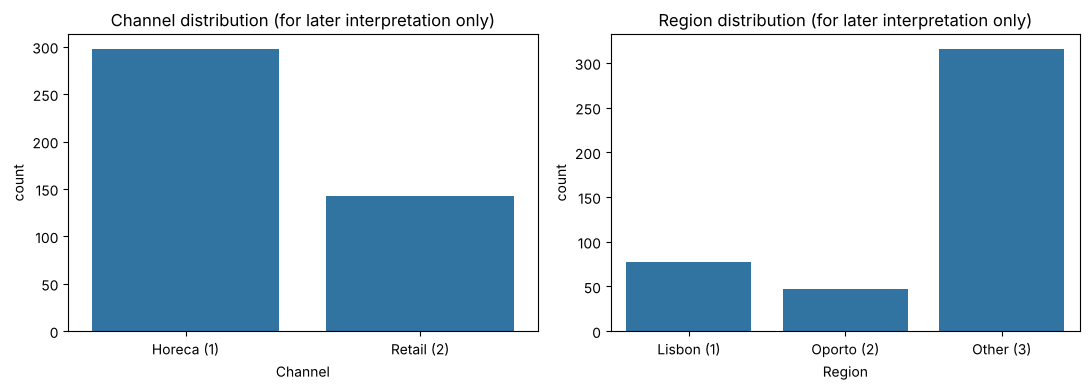

Channel
Horeca    298
Retail    142
Name: count, dtype: int64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Channel", data=df, ax=axes[0])
axes[0].set_xticklabels(["Horeca (1)", "Retail (2)"])
axes[0].set_title("Channel distribution (for later interpretation only)")
sns.countplot(x="Region", data=df, ax=axes[1])
axes[1].set_xticklabels(["Lisbon (1)", "Oporto (2)", "Other (3)"])
axes[1].set_title("Region distribution (for later interpretation only)")
plt.tight_layout()
plt.show()

print(df["Channel"].value_counts().rename({1: "Horeca", 2: "Retail"}))

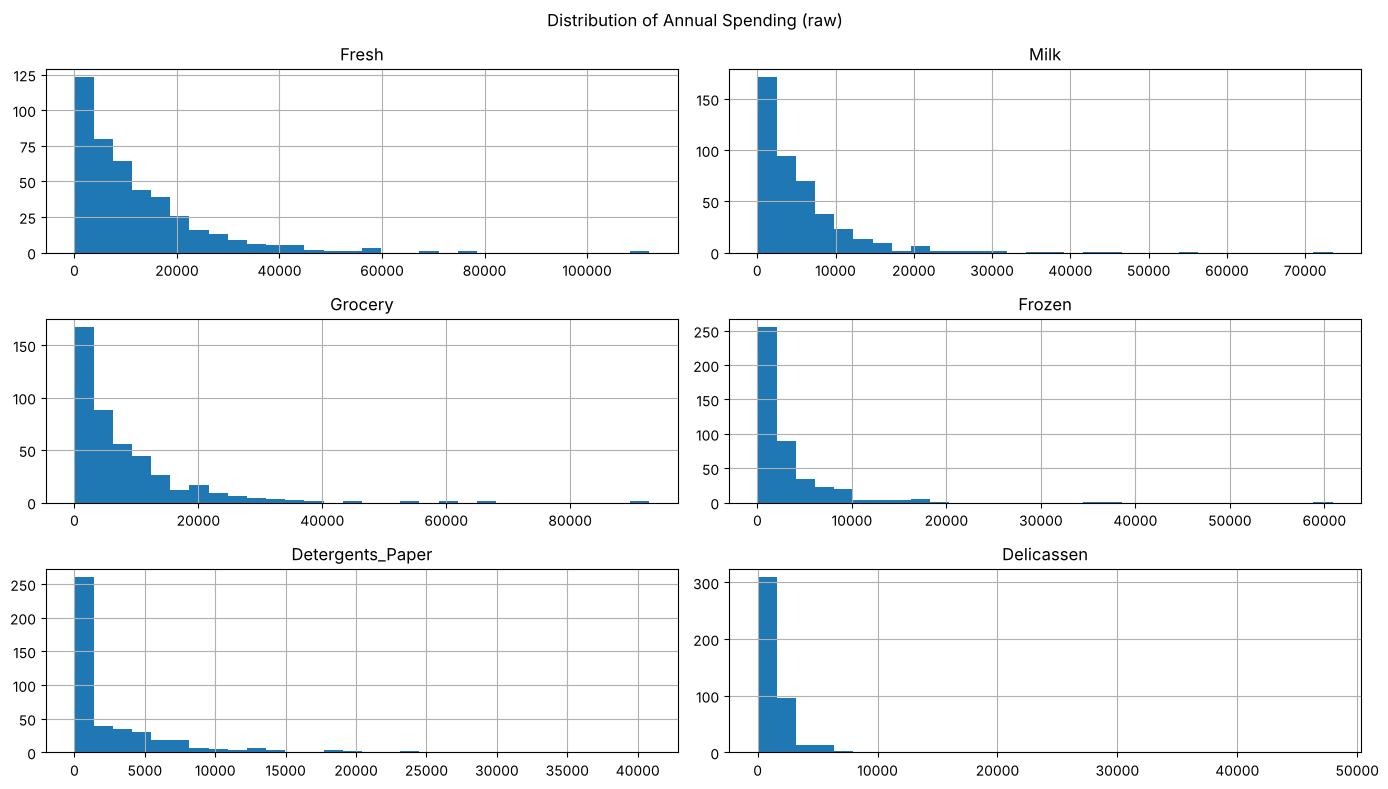

Skewness (raw):
Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15
dtype: float64


In [6]:
df[spend_cols].hist(figsize=(14, 8), bins=30)
plt.suptitle("Distribution of Annual Spending (raw)")
plt.tight_layout()
plt.show()

print("Skewness (raw):")
print(df[spend_cols].skew().round(2))

All six features are strongly right-skewed (skewness between 2.6 and 11.2). Most clients spend modest amounts, but a few very large clients spend 10–50 times the median.

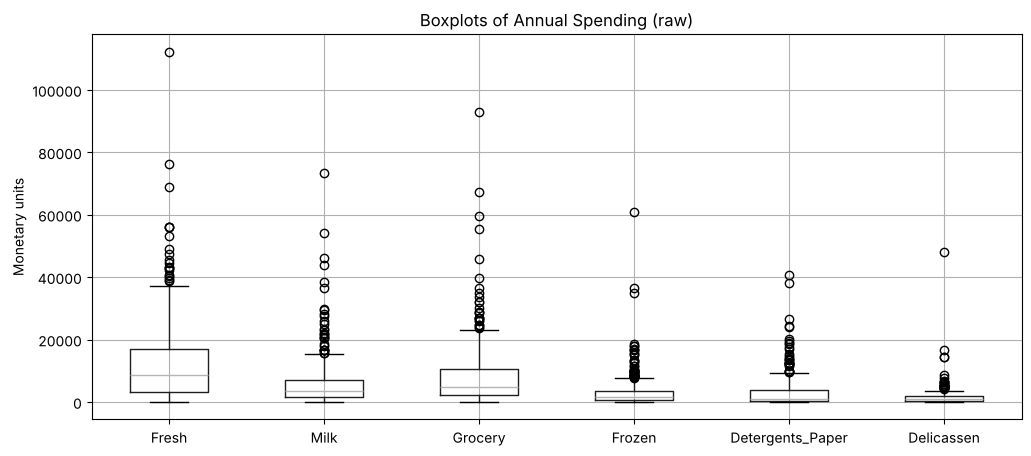

In [7]:
plt.figure(figsize=(12, 5))
df[spend_cols].boxplot()
plt.title("Boxplots of Annual Spending (raw)")
plt.ylabel("Monetary units")
plt.show()

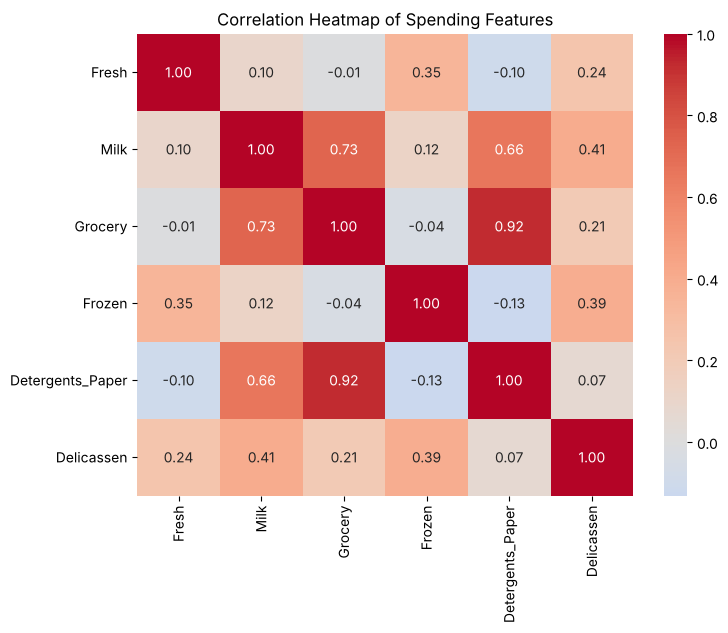

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[spend_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Spending Features")
plt.show()

- **Grocery and Detergents_Paper are very strongly correlated (0.92)**, and both correlate with Milk (0.73 and 0.66). These are the categories a supermarket-style *retail* client buys together.
- **Fresh and Frozen** correlate with each other (0.35) but hardly at all with Grocery or Detergents_Paper. This looks like the profile of a *hotel / restaurant / café* kitchen.

This already suggests two purchasing patterns, which the clustering algorithms should find without being told.

## 4. Preprocessing

### 4.1 Separate Features from Labels

`Channel` and `Region` are stored separately and are **never shown to the clustering models**.

**No train/test split.** Clustering is unsupervised: there is no target to predict and no generalisation error to estimate. The aim is to describe structure in the *whole* customer base, so every client is used for fitting. The guidelines' rule about fitting scalers on training data only applies to the supervised tracks, where a held-out test set exists. Here there is no test set to leak into.

In [9]:
X_raw = df[spend_cols].copy()
y_channel = df["Channel"]   # kept aside, NOT used for fitting
y_region = df["Region"]     # kept aside, NOT used for fitting

print("Feature matrix shape:", X_raw.shape)

Feature matrix shape: (440, 6)


### 4.2 Log Transformation

**Why this step is essential for distance-based clustering.** K-Means and Ward linkage both minimise *squared* Euclidean distances. With raw, skewed spending, one client who spends 112,000 m.u. on Fresh sits so far from everyone else that it dominates the distance calculation. The algorithms would spend their clusters isolating a few large clients instead of finding purchasing *patterns*.

The `log1p` transform, $x \rightarrow \log(1 + x)$, compresses large values and spreads out small ones:
- It turns *multiplicative* differences ("spends 3× more") into *additive* ones, which is what Euclidean distance measures.
- The `+1` keeps the transform defined if a value is 0.

                  Skew (raw)  Skew (log1p)
Fresh                   2.56         -1.58
Milk                    4.05         -0.22
Grocery                 3.59         -0.67
Frozen                  5.91         -0.35
Detergents_Paper        3.63         -0.24
Delicassen             11.15         -1.09


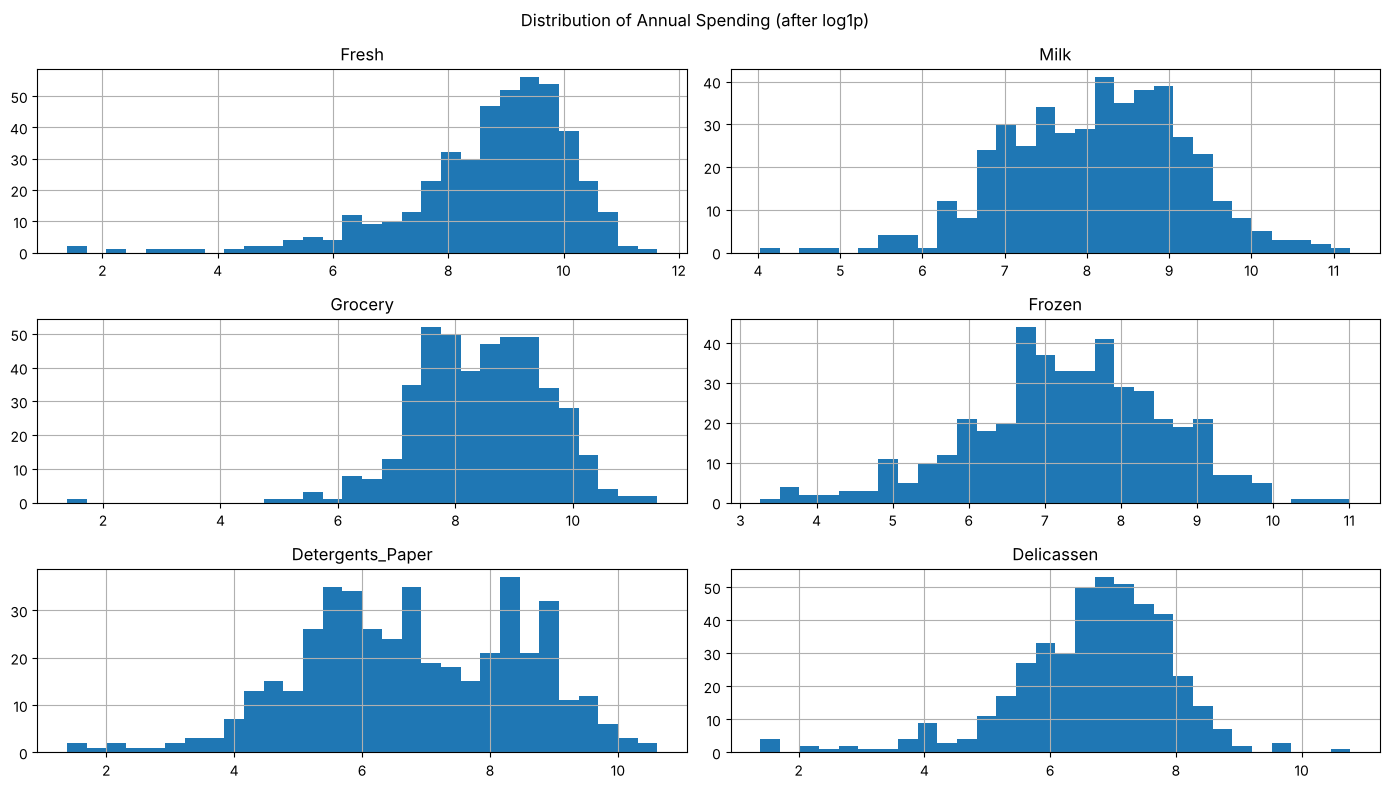

In [10]:
X_log = np.log1p(X_raw)

skew_compare = pd.DataFrame({
    "Skew (raw)": X_raw.skew(),
    "Skew (log1p)": X_log.skew()
}).round(2)
print(skew_compare)

X_log.hist(figsize=(14, 8), bins=30)
plt.suptitle("Distribution of Annual Spending (after log1p)")
plt.tight_layout()
plt.show()

After the transform, the skewness falls from 2.6–11.2 to between −1.6 and −0.2, and the histograms look roughly bell-shaped. The remaining mild left skew in `Fresh` and `Delicassen` comes from a few clients with very small spending in those categories.

### 4.3 Outlier Check (IQR on log-transformed data)

IQR outliers per feature (log scale):
Fresh               16
Milk                 4
Grocery              2
Frozen              10
Detergents_Paper     2
Delicassen          14
dtype: int64


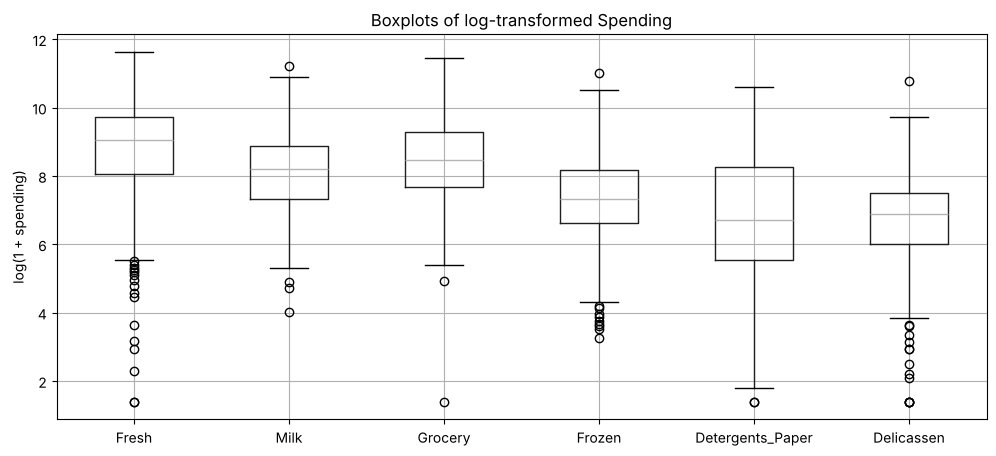

In [11]:
outlier_counts = {}
for col in spend_cols:
    Q1 = X_log[col].quantile(0.25)
    Q3 = X_log[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_counts[col] = ((X_log[col] < lower_bound) | (X_log[col] > upper_bound)).sum()

print("IQR outliers per feature (log scale):")
print(pd.Series(outlier_counts))

plt.figure(figsize=(12, 5))
X_log.boxplot()
plt.title("Boxplots of log-transformed Spending")
plt.ylabel("log(1 + spending)")
plt.show()

**Decision: keep all clients.** After the log transform, the remaining IQR outliers are mostly clients with *very low* spending in one category, for example a café that buys almost no fresh produce. These are genuine customers, not data errors, and removing them would bias the segmentation. The log transform has already taken away the extreme leverage that the very large clients had. Unlike the classification pipeline, clipping is not needed.

### 4.4 Standard Scaling

In [12]:
scaler = StandardScaler()
X_processed = scaler.fit_transform(X_log)

print("Processed shape:", X_processed.shape)
print("Means ≈ 0:", X_processed.mean(axis=0).round(3))
print("Std   ≈ 1:", X_processed.std(axis=0).round(3))

Processed shape: (440, 6)
Means ≈ 0: [ 0. -0. -0.  0. -0. -0.]
Std   ≈ 1: [1. 1. 1. 1. 1. 1.]


After the log transform, the features still differ in spread. Log(Fresh) varies more than log(Detergents_Paper), for example. Standardising gives every feature equal weight in the distance calculation, so no single product category dominates the clustering.

### 4.5 Justifying the Log Transform Empirically

To check that the log transform is the right choice, K-Means and Ward (k = 2) are fitted on **raw-scaled** and **log-scaled** data. Channel is used here only as a *post-hoc* check of whether the clusters are meaningful. It plays no part in fitting.

In [13]:
def clustering_metrics(X, labels):
    # Return the three mandatory internal validity indices for a clustering
    return {
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }

X_raw_scaled = StandardScaler().fit_transform(X_raw)

rows = []
for prep_name, X_variant in [("Raw + scaling", X_raw_scaled), ("log1p + scaling", X_processed)]:
    for algo_name, model in [
        ("K-Means", KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)),
        ("Ward", AgglomerativeClustering(n_clusters=2, linkage="ward"))
    ]:
        labels = model.fit_predict(X_variant)
        row = {"Preprocessing": prep_name, "Algorithm": algo_name,
               "Cluster sizes": str(np.bincount(labels).tolist())}
        row.update(clustering_metrics(X_variant, labels))
        row["ARI vs Channel (post-hoc)"] = adjusted_rand_score(y_channel, labels)
        rows.append(row)

pd.DataFrame(rows).round(3)

,Preprocessing,Algorithm,Cluster sizes,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,ARI vs Channel (post-hoc)
0,Raw + scaling,K-Means,"[389, 51]",0.547,1.132,153.128,0.235
1,Raw + scaling,Ward,"[434, 6]",0.792,0.909,105.442,0.023
2,log1p + scaling,K-Means,"[252, 188]",0.290,1.352,189.050,0.514
3,log1p + scaling,Ward,"[178, 262]",0.258,1.600,134.624,0.539


**This table shows why internal metrics can mislead.** On raw data, the silhouette looks *better* (0.55 for K-Means, 0.79 for Ward). However, the cluster sizes are lopsided (389 / 51 and 434 / 6): the algorithms have simply separated a handful of very large clients from everyone else. Those clusters say almost nothing about purchasing behaviour, and their ARI against Channel drops to about 0.02 for Ward.

On log-scaled data, the clusters are balanced and match the real business channels much better (ARI ≈ 0.51–0.54). **The log-scaled data is used for all models below.** A high silhouette from isolating outliers is not a better segmentation.

## 5. K-Means Clustering

K-Means places *k* centroids and repeatedly (i) assigns each client to its nearest centroid and (ii) moves each centroid to the mean of its assigned clients. This minimises the **inertia** (within-cluster sum of squares, WCSS):

$$\text{Inertia} = \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$$

Inertia always falls as *k* grows, so the smallest value cannot be used to pick *k*. The **Elbow method** looks for the *k* after which adding more clusters only gives small reductions in inertia.

### 5.1 Elbow Curve (Inertia vs. k)

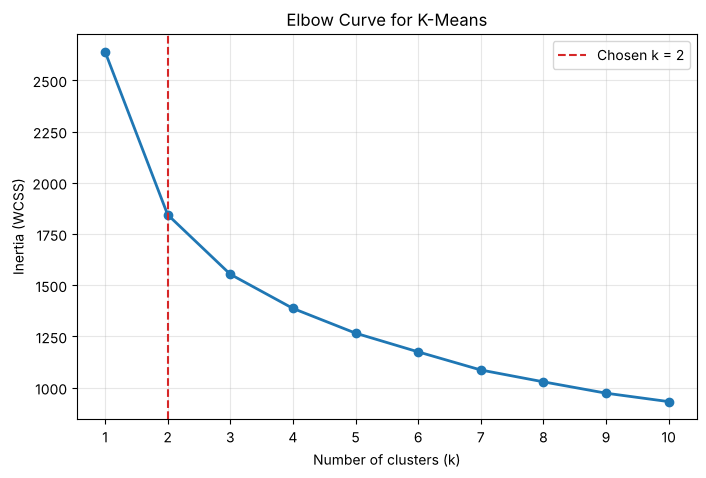

k = 1 -> 2: inertia drops by   795.9 (30.1%)
k = 2 -> 3: inertia drops by   290.6 (15.8%)
k = 3 -> 4: inertia drops by   166.6 (10.7%)
k = 4 -> 5: inertia drops by   120.7 ( 8.7%)
k = 5 -> 6: inertia drops by    91.4 ( 7.2%)
k = 6 -> 7: inertia drops by    88.4 ( 7.5%)
k = 7 -> 8: inertia drops by    57.9 ( 5.3%)
k = 8 -> 9: inertia drops by    55.3 ( 5.4%)
k = 9 -> 10: inertia drops by    41.1 ( 4.2%)


In [14]:
k_range = range(1, 11)
inertia = []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X_processed)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertia, "o-", color="#1f77b4", linewidth=2)
plt.axvline(2, color="#d62728", linestyle="--", label="Chosen k = 2")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Curve for K-Means")
plt.xticks(list(k_range))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for k in range(2, 11):
    drop = inertia[k-2] - inertia[k-1]
    print(f"k = {k-1} -> {k}: inertia drops by {drop:7.1f} ({drop / inertia[k-2] * 100:4.1f}%)")

The elbow is at **k = 2**. Going from 1 to 2 clusters removes 30% of the inertia. The next step (2 → 3) removes only about 16%, and every later step removes 11% or less. The internal validity indices are also computed for each *k* to confirm this.

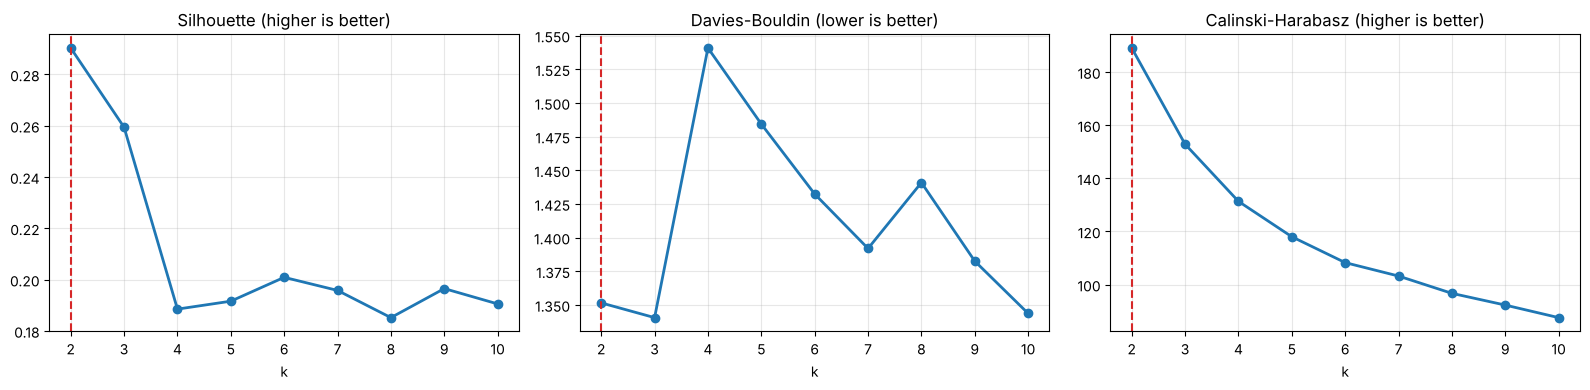

,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
k,,,
2,0.290,1.352,189.050
3,0.259,1.341,152.835
4,0.188,1.541,131.320
5,0.192,1.484,118.000
6,0.201,1.432,108.263
7,0.196,1.392,103.208
8,0.185,1.441,96.699
9,0.197,1.383,92.281
10,0.191,1.344,87.559


In [15]:
scores_k = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_processed)
    row = {"k": k}
    row.update(clustering_metrics(X_processed, labels))
    scores_k.append(row)

scores_k = pd.DataFrame(scores_k).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
titles = ["Silhouette (higher is better)", "Davies-Bouldin (lower is better)", "Calinski-Harabasz (higher is better)"]
for ax, col, title in zip(axes, scores_k.columns, titles):
    ax.plot(scores_k.index, scores_k[col], "o-", color="#1f77b4", linewidth=2)
    ax.axvline(2, color="#d62728", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

scores_k.round(3)

**Choice of k = 2.** Silhouette and Calinski-Harabasz are both clearly highest at k = 2. Davies-Bouldin is almost flat across *k* (about 1.34–1.54), so it does not separate the options strongly: k = 2 (1.352) is within 0.01 of the best value (k = 3, 1.341). The elbow, Silhouette and Calinski-Harabasz all point to the same answer, so **k = 2** is used.

### 5.2 Fit the Final K-Means Model

In [16]:
kmeans = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_processed)

print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("\nFinal inertia:", round(kmeans.inertia_, 2))

Cluster sizes:
0    252
1    188
Name: count, dtype: int64

Final inertia: 1844.06


In [17]:
# Convert centroids back to monetary units: undo the scaling, then undo log1p
centroids_mu = np.expm1(scaler.inverse_transform(kmeans.cluster_centers_))
pd.DataFrame(centroids_mu, columns=spend_cols,
             index=[f"Cluster {i}" for i in range(2)]).round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster 0,8581.0,1754.0,2274.0,2064.0,287.0,649.0
Cluster 1,4014.0,8062.0,12051.0,954.0,4036.0,1022.0


The centroids, converted back to monetary units, show the two purchasing patterns:
- **Cluster 0:** high spending on **Fresh** and **Frozen**, low spending on Milk, Grocery and Detergents_Paper. This is a hotel / restaurant / café profile.
- **Cluster 1:** high spending on **Grocery, Milk and Detergents_Paper**. This is a retail / supermarket profile.

### 5.3 K-Means Evaluation Metrics

In [18]:
kmeans_scores = clustering_metrics(X_processed, kmeans_labels)
for name, value in kmeans_scores.items():
    print(f"{name:25s}: {value:.3f}")

Silhouette Score         : 0.290
Davies-Bouldin Index     : 1.352
Calinski-Harabasz Index  : 189.050


## 6. Agglomerative Hierarchical Clustering

Agglomerative clustering works **bottom-up**. Every client starts as its own cluster, and at each step the two *closest* clusters are merged until one remains. The **linkage** criterion defines "closest":

| Linkage | Distance between clusters A and B |
|---|---|
| **Ward** | Increase in total within-cluster variance if A and B merge (the same objective as K-Means) |
| **Complete** | Maximum distance between any point in A and any point in B |
| **Average** | Mean distance over all pairs of points in A and B |
| **Single** | Minimum distance between any point in A and any point in B |

The full merge history is drawn as a **dendrogram**. The height of each merge is the linkage distance, so cutting the tree horizontally gives a flat clustering.

### 6.1 Dendrograms – Comparing Linkage Strategies

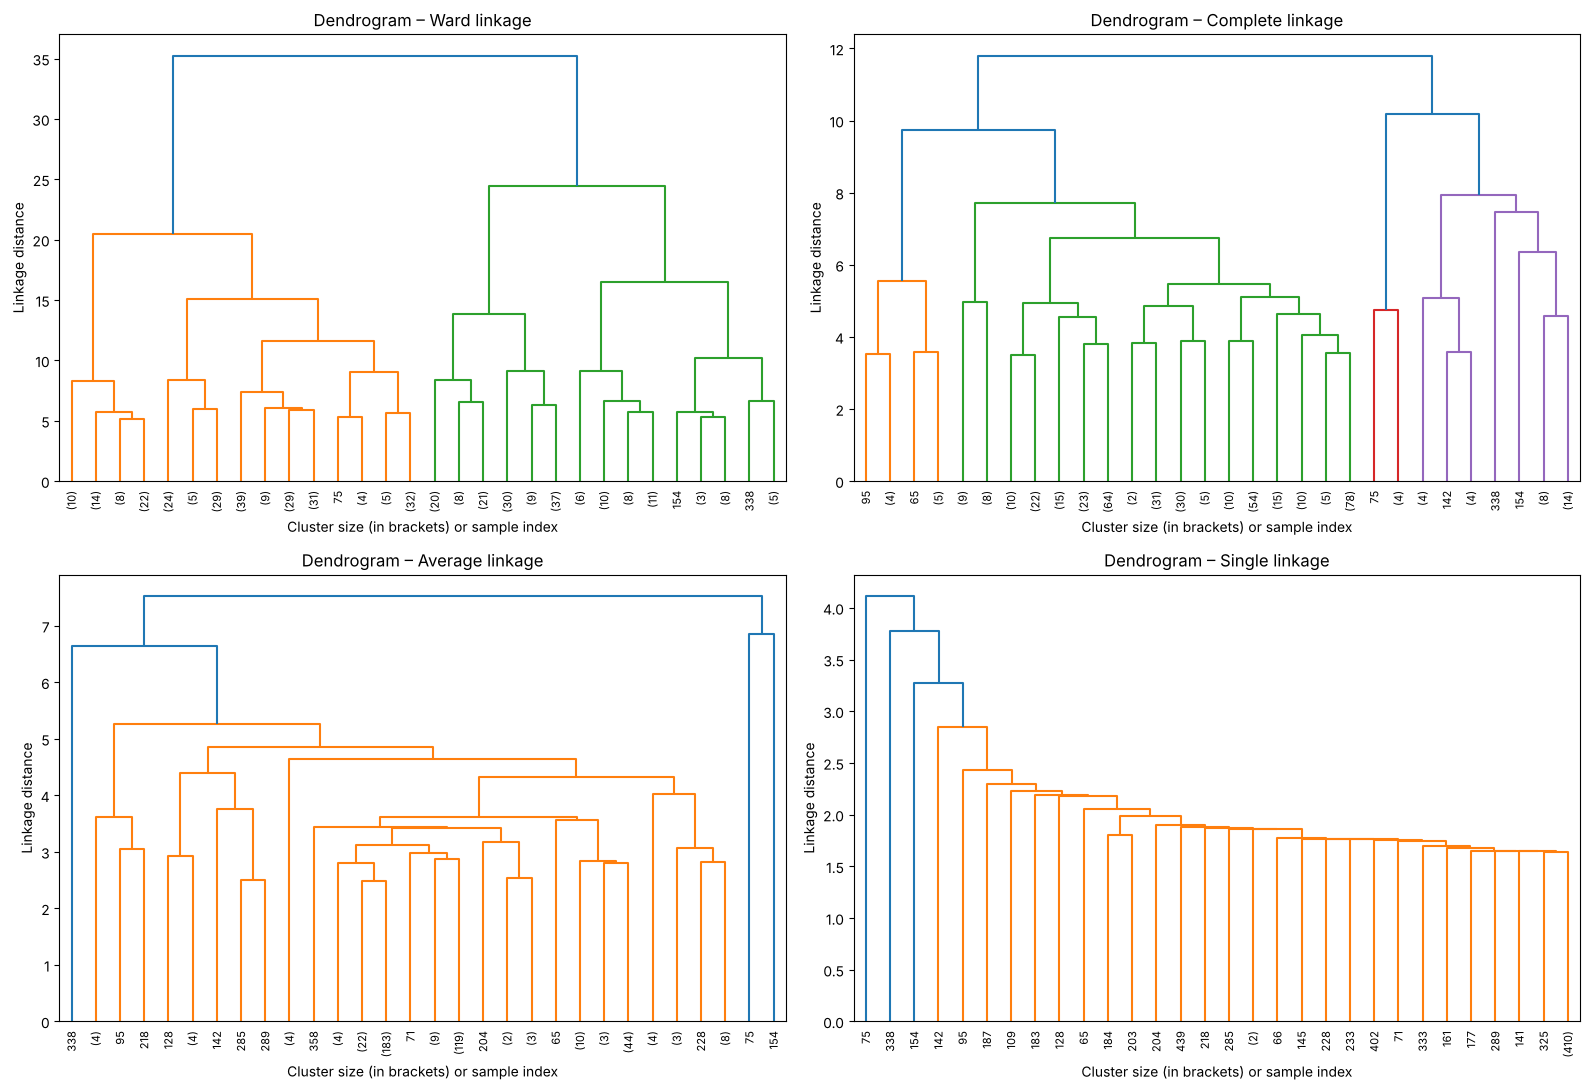

In [19]:
linkage_methods = ["ward", "complete", "average", "single"]
linkage_matrices = {m: linkage(X_processed, method=m) for m in linkage_methods}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, method in zip(axes.flatten(), linkage_methods):
    dendrogram(
        linkage_matrices[method],
        truncate_mode="lastp",   # show only the last p merged clusters
        p=30,
        show_leaf_counts=True,
        leaf_rotation=90,
        leaf_font_size=8,
        ax=ax
    )
    ax.set_title(f"Dendrogram – {method.capitalize()} linkage")
    ax.set_xlabel("Cluster size (in brackets) or sample index")
    ax.set_ylabel("Linkage distance")
plt.tight_layout()
plt.show()

The dendrograms show how differently the linkages behave:
- **Ward** gives a balanced tree with one tall final merge, meaning two well-separated groups of comparable size.
- **Complete** is less balanced. Its top merges split off smaller groups of clients with unusual spending.
- **Average** and **single** show *chaining*: clients are added one by one to a single growing cluster, and the top merges only peel off one or two outlying clients.

### 6.2 Quantitative Comparison of Linkages (k = 2)

In [20]:
linkage_results = []
for method in linkage_methods:
    labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X_processed)
    row = {"Linkage": method, "Cluster sizes": str(np.bincount(labels).tolist())}
    row.update(clustering_metrics(X_processed, labels))
    linkage_results.append(row)

linkage_results = pd.DataFrame(linkage_results).set_index("Linkage")
linkage_results.round(3)

,Cluster sizes,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
Linkage,,,,
ward,"[178, 262]",0.258,1.600,134.624
complete,"[38, 402]",0.322,1.554,61.992
average,"[2, 438]",0.569,0.883,13.965
single,"[439, 1]",0.570,0.307,8.964


**Interpreting the comparison.**
- **Single** and **average** linkage get the highest Silhouette, and single linkage the lowest Davies-Bouldin. Their cluster sizes are [439, 1] and [2, 438], though: one "cluster" is just one or two unusual clients. A lone point far from everything else is trivially "well separated", which inflates those scores. The **Calinski-Harabasz** index exposes this: it collapses to 9–14.
- **Complete** linkage has a higher Silhouette than Ward (0.32 vs 0.26), but only because it splits off a small group of 38 unusual clients from the other 402. Its Calinski-Harabasz (about 62) is less than half of Ward's.
- **Ward** linkage gives a balanced, meaningful [178, 262] split with by far the highest Calinski-Harabasz (≈ 135). It also optimises the same variance criterion as K-Means, which suits compact segments.

**Ward linkage is therefore selected.** Internal metrics must always be read together with cluster sizes.

### 6.3 Choosing the Number of Clusters from the Ward Dendrogram

Cutting into 2 clusters -> vertical gap = 10.78
Cutting into 3 clusters -> vertical gap = 3.98
Cutting into 4 clusters -> vertical gap = 4.00
Cutting into 5 clusters -> vertical gap = 1.39
Cutting into 6 clusters -> vertical gap = 1.23

Largest gap -> k = 2, cut at height ≈ 29.84


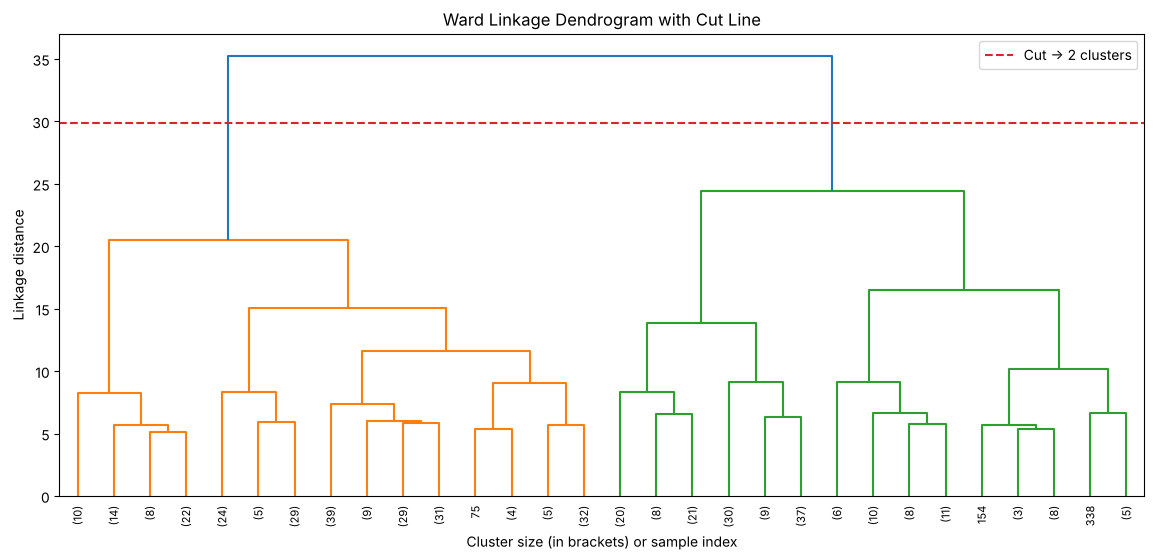

In [21]:
Z_ward = linkage_matrices["ward"]

# Gap between successive merge heights, starting from the top of the tree
merge_heights = Z_ward[:, 2][::-1]          # largest merge first
gaps = merge_heights[:-1] - merge_heights[1:]
for k in range(2, 7):
    print(f"Cutting into {k} clusters -> vertical gap = {gaps[k-2]:.2f}")

best_k_dendro = int(np.argmax(gaps[:8]) + 2)
cut_height = (merge_heights[best_k_dendro - 2] + merge_heights[best_k_dendro - 1]) / 2
print(f"\nLargest gap -> k = {best_k_dendro}, cut at height ≈ {cut_height:.2f}")

plt.figure(figsize=(14, 6))
dendrogram(Z_ward, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, leaf_font_size=8, color_threshold=cut_height)
plt.axhline(cut_height, color="#d62728", linestyle="--", label=f"Cut → {best_k_dendro} clusters")
plt.title("Ward Linkage Dendrogram with Cut Line")
plt.xlabel("Cluster size (in brackets) or sample index")
plt.ylabel("Linkage distance")
plt.legend()
plt.show()

The largest vertical gap in the Ward dendrogram (≈ 10.8) is at the top merge, far larger than any gap below it (about 4 or less). The horizontal cut that crosses the longest uninterrupted vertical lines gives **2 clusters**, which matches the K-Means elbow.

### 6.4 Fit the Final Agglomerative Model

In [22]:
agglo = AgglomerativeClustering(n_clusters=2, metric="euclidean", linkage="ward")
agglo_labels = agglo.fit_predict(X_processed)

# Cluster numbers are arbitrary. Flip Ward's numbering if needed so that the same
# segment has the same number (and colour) as in K-Means. This only renames clusters.
if (agglo_labels == kmeans_labels).mean() < 0.5:
    agglo_labels = 1 - agglo_labels

print("Cluster sizes:")
print(pd.Series(agglo_labels).value_counts().sort_index())

Cluster sizes:
0    262
1    178
Name: count, dtype: int64


### 6.5 Agglomerative Evaluation Metrics

In [23]:
agglo_scores = clustering_metrics(X_processed, agglo_labels)
for name, value in agglo_scores.items():
    print(f"{name:25s}: {value:.3f}")

Silhouette Score         : 0.258
Davies-Bouldin Index     : 1.600
Calinski-Harabasz Index  : 134.624


## 7. Evaluation Metrics – Comparison of Algorithms

| Metric | Range | Better | What it measures |
|---|---|---|---|
| **Silhouette** | −1 to 1 | Higher | For each point: (b − a) / max(a, b), where *a* = mean distance to its own cluster and *b* = mean distance to the nearest other cluster |
| **Davies-Bouldin** | ≥ 0 | Lower | Average over clusters of the worst ratio (spread_i + spread_j) / distance(centroid_i, centroid_j) |
| **Calinski-Harabasz** | ≥ 0 | Higher | Between-cluster dispersion ÷ within-cluster dispersion, adjusted for *n* and *k* |

In [24]:
summary = pd.DataFrame({
    "K-Means (k=2)": kmeans_scores,
    "Agglomerative – Ward (k=2)": agglo_scores
}).T
summary["Cluster sizes"] = [str(np.bincount(kmeans_labels).tolist()),
                            str(np.bincount(agglo_labels).tolist())]
summary.round(3)

,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Cluster sizes
K-Means (k=2),0.290,1.352,189.050,"[252, 188]"
Agglomerative – Ward (k=2),0.258,1.600,134.624,"[262, 178]"


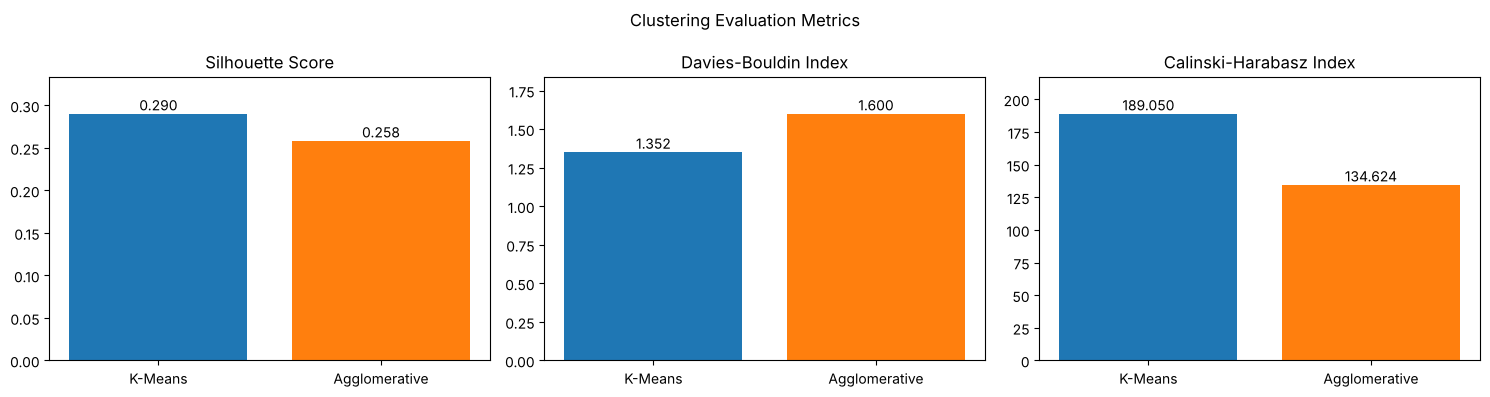

In [25]:
metric_cols = ["Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Index"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, metric_cols):
    bars = ax.bar(["K-Means", "Agglomerative"], summary[metric].astype(float), color=CLUSTER_COLORS[:2])
    ax.set_title(metric)
    ax.bar_label(bars, fmt="%.3f")
    ax.margins(y=0.15)
plt.suptitle("Clustering Evaluation Metrics")
plt.tight_layout()
plt.show()

**K-Means is better on all three metrics:** higher Silhouette, lower Davies-Bouldin and higher Calinski-Harabasz. This is expected. K-Means directly optimises the compact, centroid-based structure that these indices reward. Ward builds its clusters greedily, one merge at a time, and can never undo an early merge.

### 7.1 Interpreting the Score Values

**Silhouette ≈ 0.29.** On the Kaufman & Rousseeuw scale (> 0.70 strong, 0.51–0.70 reasonable, 0.26–0.50 weak, ≤ 0.25 no substantial structure), this is *weak but real* structure. Business customers form a **spectrum** of purchasing behaviour rather than two perfectly separate types. Some cafés buy like small shops, and some shops sell fresh food. Clients near the boundary have silhouette values close to 0, which pulls the average down. The per-client silhouette plot below shows this. Only about 2% of clients are negative (closer to the other cluster), and the Retail-like cluster has the lower average because it contains a mix of shops and larger cafés.

**Davies-Bouldin ≈ 1.35.** A value above 1 means each cluster's spread is larger than the distance between the two centroids, so the clusters overlap at their edges. This agrees with the silhouette.

**Calinski-Harabasz ≈ 189.** CH has no absolute scale. It grows with the number of samples, so it can only be compared across *k* or across algorithms on the same data. Its job here is to support the choice of *k*: it is highest at k = 2.

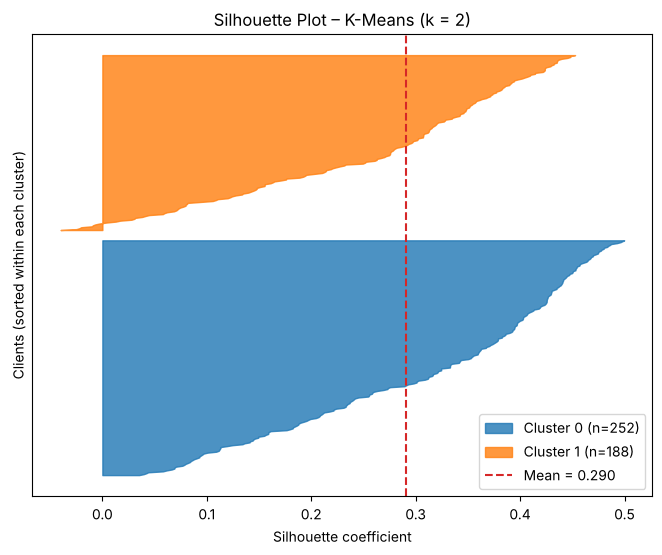

Clients with negative silhouette: 1.8%
Mean silhouette, cluster 0: 0.313
Mean silhouette, cluster 1: 0.260


In [26]:
sil_values = silhouette_samples(X_processed, kmeans_labels)

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for c in range(2):
    c_sil = np.sort(sil_values[kmeans_labels == c])
    y_upper = y_lower + len(c_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil,
                     color=CLUSTER_COLORS[c], alpha=0.8, label=f"Cluster {c} (n={len(c_sil)})")
    y_lower = y_upper + 10
ax.axvline(sil_values.mean(), color="#d62728", linestyle="--", label=f"Mean = {sil_values.mean():.3f}")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Clients (sorted within each cluster)")
ax.set_title("Silhouette Plot – K-Means (k = 2)")
ax.set_yticks([])
ax.legend()
plt.show()

print(f"Clients with negative silhouette: {(sil_values < 0).mean() * 100:.1f}%")
for c in range(2):
    print(f"Mean silhouette, cluster {c}: {sil_values[kmeans_labels == c].mean():.3f}")

## 8. Cluster Visualisation

### 8.1 PCA-Reduced 2-D Scatter Plots

PCA projects the 6-dimensional processed data onto the two directions of greatest variance. This is a *linear* projection used only for visualisation; the models were fitted on all 6 features.

Variance explained: PC1 = 44.1%, PC2 = 27.2%, total = 71.3%


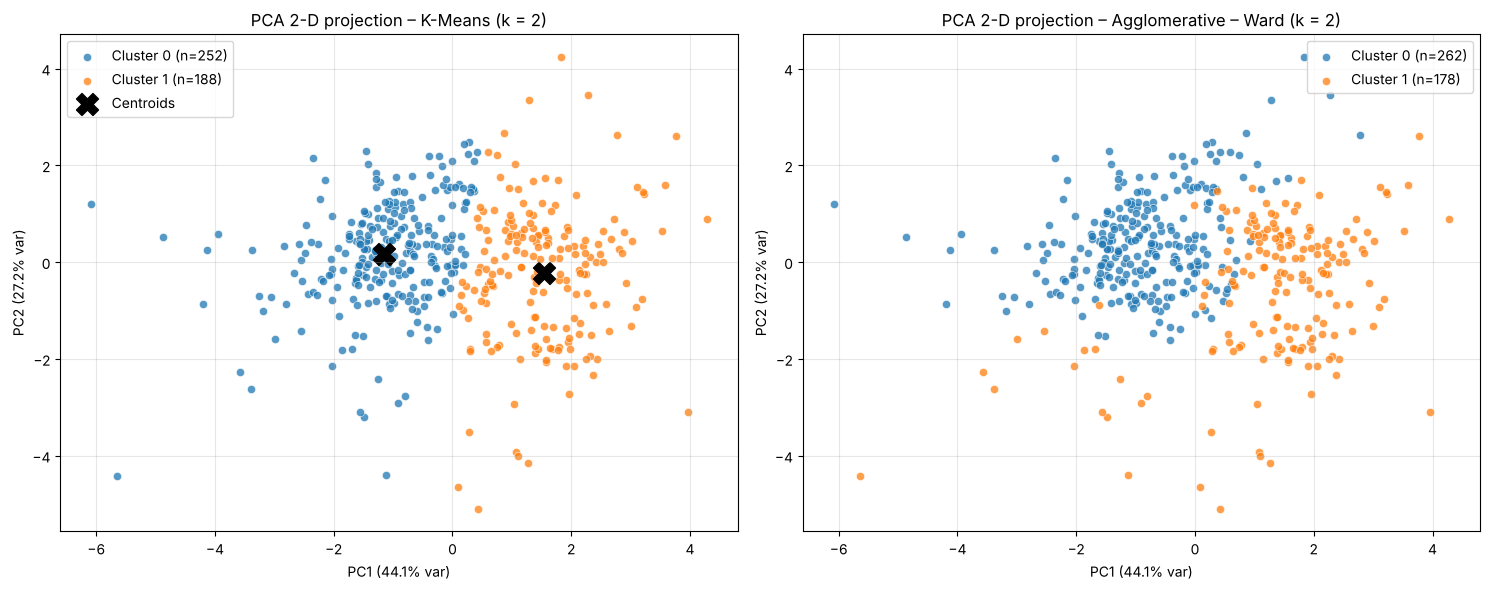

In [27]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_processed)

explained = pca_2d.explained_variance_ratio_
print(f"Variance explained: PC1 = {explained[0]*100:.1f}%, PC2 = {explained[1]*100:.1f}%, "
      f"total = {explained.sum()*100:.1f}%")

kmeans_centers_2d = pca_2d.transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in zip(
        axes,
        [kmeans_labels, agglo_labels],
        ["K-Means (k = 2)", "Agglomerative – Ward (k = 2)"]):
    for c in np.unique(labels):
        mask = labels == c
        ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], s=35, alpha=0.75,
                   color=CLUSTER_COLORS[c], edgecolor="white", linewidth=0.5,
                   label=f"Cluster {c} (n={mask.sum()})")
    ax.set_title(f"PCA 2-D projection – {title}")
    ax.set_xlabel(f"PC1 ({explained[0]*100:.1f}% var)")
    ax.set_ylabel(f"PC2 ({explained[1]*100:.1f}% var)")
    ax.grid(alpha=0.3)

axes[0].scatter(kmeans_centers_2d[:, 0], kmeans_centers_2d[:, 1], marker="X", s=250,
                c="black", label="Centroids")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

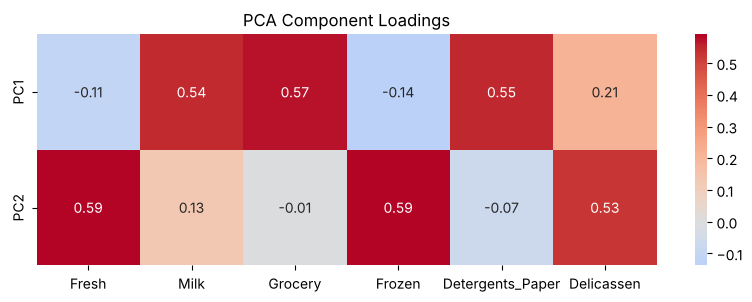

In [28]:
# Which spending categories drive the two principal components?
component_df = pd.DataFrame(pca_2d.components_, index=["PC1", "PC2"], columns=spend_cols)
plt.figure(figsize=(10, 3))
sns.heatmap(component_df, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("PCA Component Loadings")
plt.show()

- **PC1** is driven mainly by **Grocery, Detergents_Paper and Milk**, the "retail basket". The two clusters separate mostly along this axis.
- **PC2** is driven mainly by **Fresh, Frozen and Delicassen**, the "kitchen basket".

The clusters therefore split along exactly the retail-versus-kitchen pattern seen in the correlation heatmap.

### 8.2 t-SNE Plots

t-SNE is a *non-linear* embedding. It keeps **local neighbourhoods** (clients close in 6-D stay close in 2-D), so it can show structure that PCA misses. In a t-SNE plot, distances between far-apart groups and the sizes of clusters are not meaningful; only which points are neighbours is meaningful. t-SNE is shown for both algorithms, which goes beyond the minimum of one required by the guidelines.

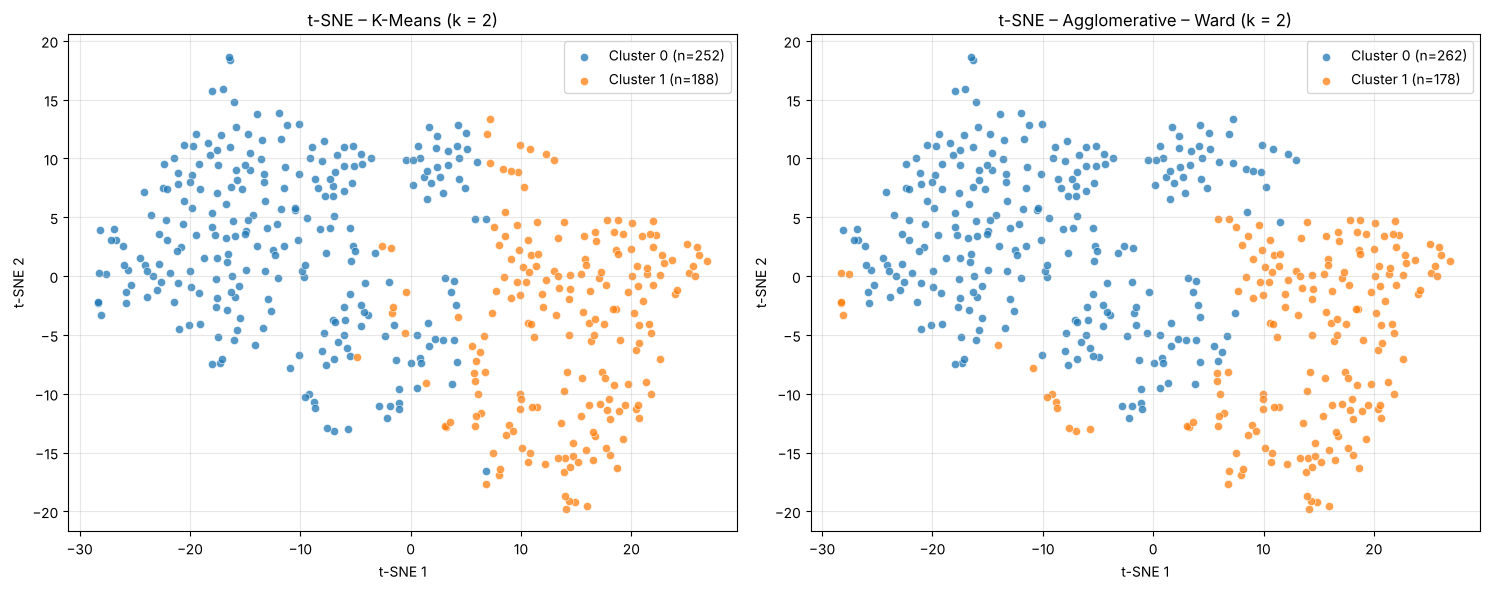

In [29]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_processed)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in zip(
        axes,
        [kmeans_labels, agglo_labels],
        ["K-Means (k = 2)", "Agglomerative – Ward (k = 2)"]):
    for c in np.unique(labels):
        mask = labels == c
        ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=35, alpha=0.75,
                   color=CLUSTER_COLORS[c], edgecolor="white", linewidth=0.5,
                   label=f"Cluster {c} (n={mask.sum()})")
    ax.set_title(f"t-SNE – {title}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Post-hoc Interpretation with Ground-Truth Labels

The models are now fitted. **Only at this point** are `Channel` and `Region` used, to check whether the unsupervised segments match real business categories. These labels did **not** influence any modelling choice above, apart from the clearly labelled post-hoc sanity check in Section 4.5.

- **Adjusted Rand Index (ARI):** agreement between two partitions, corrected for chance (0 = random, 1 = identical).
- **Normalised Mutual Information (NMI):** how much knowing the cluster tells you about the label (0 to 1).

In [30]:
channel_names = y_channel.map({1: "Horeca", 2: "Retail"})

for name, labels in [("K-Means", kmeans_labels), ("Agglomerative (Ward)", agglo_labels)]:
    print(f"===== {name} =====")
    ct = pd.crosstab(labels, channel_names, rownames=["Cluster"], colnames=["Channel"])
    ct["% Horeca"] = (ct["Horeca"] / ct.sum(axis=1) * 100).round(1)
    print(ct)
    print(f"ARI vs Channel = {adjusted_rand_score(y_channel, labels):.3f}")
    print(f"NMI vs Channel = {normalized_mutual_info_score(y_channel, labels):.3f}")
    print(f"ARI vs Region  = {adjusted_rand_score(y_region, labels):.3f}")
    print()

===== K-Means =====
Channel  Horeca  Retail  % Horeca
Cluster                          
0           244       8      96.8
1            54     134      28.7
ARI vs Channel = 0.514
NMI vs Channel = 0.445
ARI vs Region  = -0.008

===== Agglomerative (Ward) =====
Channel  Horeca  Retail  % Horeca
Cluster                          
0           251      11      95.8
1            47     131      26.4
ARI vs Channel = 0.539
NMI vs Channel = 0.447
ARI vs Region  = -0.008



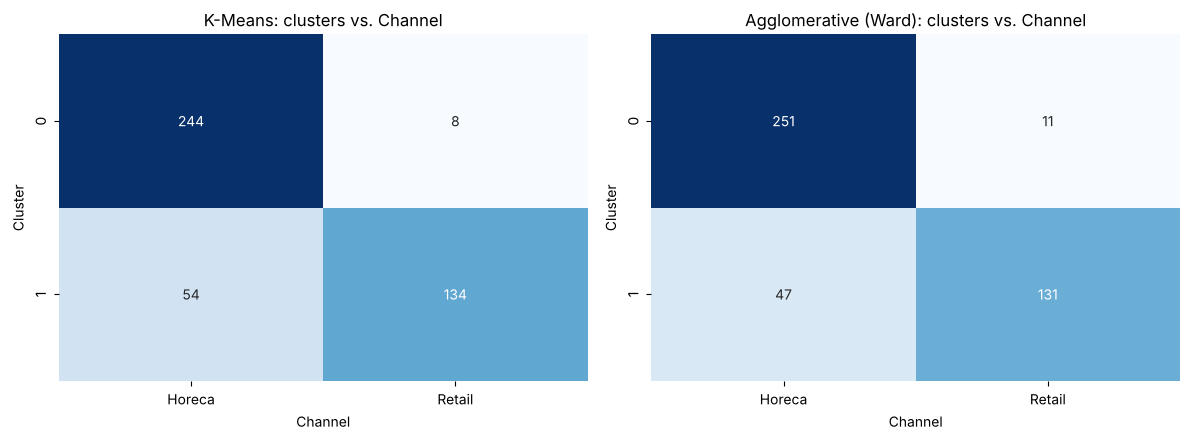

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, labels, title in zip(axes, [kmeans_labels, agglo_labels], ["K-Means", "Agglomerative (Ward)"]):
    ct = pd.crosstab(labels, channel_names, rownames=["Cluster"], colnames=["Channel"])
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{title}: clusters vs. Channel")
plt.tight_layout()
plt.show()

- **Channel:** both algorithms find a segment that is almost entirely Horeca. In K-Means cluster 0, **244 of 252 clients (96.8%)** are hotels, restaurants or cafés. The other segment is mostly Retail (71% for K-Means, 74% for Ward). ARI ≈ 0.51–0.54 shows strong agreement with a business category the models never saw.
- **Region:** ARI ≈ 0 for both algorithms. Purchasing behaviour does **not** depend on whether a client is in Lisbon, Oporto or elsewhere. This is a useful negative result: the segments reflect *what kind of business* a client is, not *where* it is.
- The Retail-dominated cluster also contains some Horeca clients. These are probably larger cafés or catering businesses that buy grocery and paper goods in bulk. This is the overlap that keeps the silhouette moderate.

### 9.1 Segment Profiles (in monetary units)

In [32]:
profile_df = X_raw.copy()
profile_df["Segment"] = kmeans_labels

segment_median = profile_df.groupby("Segment")[spend_cols].median()
segment_median["Total (median of sums)"] = profile_df.assign(
    Total=X_raw.sum(axis=1)).groupby("Segment")["Total"].median()
segment_median["n clients"] = profile_df["Segment"].value_counts().sort_index()
segment_median.round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total (median of sums),n clients
Segment,,,,,,,,
0,10348.0,1871.0,2406.0,2225.0,328.0,750.0,19745.0,252
1,5406.0,7690.0,11527.0,1062.0,4495.0,1388.0,35222.0,188


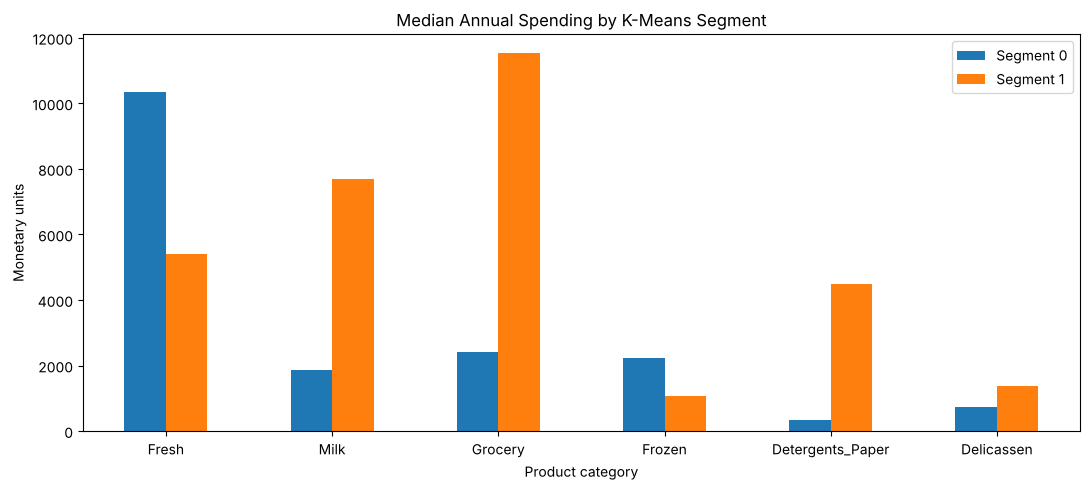

In [33]:
segment_median[spend_cols].T.plot(kind="bar", figsize=(11, 5), color=CLUSTER_COLORS[:2])
plt.title("Median Annual Spending by K-Means Segment")
plt.ylabel("Monetary units")
plt.xlabel("Product category")
plt.xticks(rotation=0)
plt.legend([f"Segment {i}" for i in range(2)])
plt.tight_layout()
plt.show()

| Segment | Profile | Business interpretation |
|---|---|---|
| **0 – "Kitchen buyers"** | High **Fresh** and **Frozen**, very low Detergents_Paper and Grocery | Hotels, restaurants and cafés that cook on site |
| **1 – "Retail buyers"** | High **Grocery, Milk and Detergents_Paper**, lower Fresh | Shops and supermarkets restocking shelves |

**Possible business actions:**
- Segment 0 needs frequent, chilled deliveries of perishables.
- Segment 1 suits bulk, less frequent deliveries of packaged goods, with volume discounts on grocery and paper products.

## 10. Conclusion

**Preprocessing.** The spending data was extremely right-skewed (skewness up to 11.2). A `log1p` transform followed by standard scaling was essential. Without it, both algorithms produced high but meaningless scores by separating a handful of very large clients, for example a 434 / 6 split with silhouette 0.79.

**Choosing k.** The K-Means elbow curve bends sharply at **k = 2**, where Silhouette and Calinski-Harabasz are also highest. The largest vertical gap in the Ward dendrogram also gives **2 clusters**.

**Linkage comparison.** Ward linkage gave the only balanced, meaningful hierarchical partition. Single and average linkage split off one or two outlying clients (inflated Silhouette, Calinski-Harabasz ≈ 9–14), and complete linkage produced a lopsided 38 / 402 split.

**Algorithm comparison.** K-Means is better on all three metrics (Silhouette 0.290 vs 0.258, Davies-Bouldin 1.35 vs 1.60, Calinski-Harabasz 189 vs 135), because it directly optimises compact clusters while Ward merges greedily. The two partitions largely agree with each other (ARI ≈ 0.64 between them).

**Cluster quality.** A silhouette of about 0.29 means real but overlapping structure. Customer purchasing behaviour is a spectrum, and the PCA and t-SNE plots show a dense boundary region between the two segments.

**Post-hoc validation.** Without seeing labels, both algorithms rediscovered the **Horeca vs Retail** split (ARI ≈ 0.51–0.54; one segment is about 97% Horeca). Segments are unrelated to **Region** (ARI ≈ 0). The result is two actionable segments: *kitchen buyers* (Fresh and Frozen) and *retail buyers* (Grocery, Milk and Detergents_Paper).